# Quantum portfolio selection with QAOA: thesis, antithesis, synthesis

**Qiskit Fall Fest 2026, Miami Dade College. Theme: quantum portfolio optimisation.**

**The problem.** A fund must hold exactly *B* of *n* stocks. Which *B* give the best trade-off between
return and risk? With 16 stocks and *B* = 8 there are 12,870 choices; with 60 stocks there are more
than 10^17. This is the mean-variance selection problem that asset managers solve when they rebalance.

**How this notebook works.** Each section states a design claim (thesis), tries to break it with a
check that could fail (antithesis), and keeps only what survives (synthesis). Heavy experiments live in
`experiments/` and write `results/*.json`; this notebook re-runs the small ones live and plots the rest.

**Hardware note.** The theme names IBM's 127-qubit `ibm_brisbane`. That device was retired on
2025-11-03, so every "Brisbane" number here is a noisy *simulation* using `FakeBrisbane`, IBM's snapshot
of its layout, gates and calibration. Nothing in this notebook ran on a real quantum computer.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")

from qpo.data import load_prices, annualised_stats
from qpo.problem import PortfolioProblem
from qpo.hamiltonian import build_cost_hamiltonian, build_defective_hamiltonian, verify
from qpo.ansatz import build_qaoa_circuit, bind_vector, fourier_schedule
from qpo.fastsim import FastQAOA
from qpo.metrics import summarise, counts_to_probs
from qpo.instances import make_pool
from qpo import classical

results = lambda name: json.loads(Path(f"results/{name}.json").read_text())
prices = load_prices()
print(f"{prices.shape[1]} stocks, {len(prices)} trading days, {prices.index[0].date()} to {prices.index[-1].date()}")

16 stocks, 1254 trading days, 2021-01-04 to 2025-12-30


## 1. The problem, with no quantum in it

`PortfolioProblem.cost` is the single source of truth: risk aversion times portfolio variance, minus
portfolio return, for an equal-weight portfolio of the selected stocks. Everything later is checked
against it by brute force.

In [2]:
mu, sigma, names = annualised_stats(prices, ("AAPL", "JPM", "XOM", "JNJ"), "2024-01-01", "2025-12-31")
toy = PortfolioProblem(mu, sigma, budget=2, risk_aversion=3.0, tickers=names)
for index in sorted(np.flatnonzero(toy.feasible_mask), key=lambda z: toy.cost_vector[z]):
    print(f"{'+'.join(toy.names(int(index))):10s} cost {toy.cost_vector[index]:+.4f}")
print("optimum:", toy.names(toy.best_index))

JPM+JNJ    cost -0.1751
AAPL+JPM   cost -0.1370
JPM+XOM    cost -0.1255
AAPL+JNJ   cost -0.0961
XOM+JNJ    cost -0.0728
AAPL+XOM   cost -0.0459
optimum: ('JPM', 'JNJ')


## 2. Thesis 1: "the Hamiltonian is the cost function"

QAOA needs the cost written as an Ising Hamiltonian. The claim is the identity
`cost(x) = scale * <x|H|x> + offset` for every bitstring.

**Antithesis.** Check all 16 bitstrings. The second build below reproduces two bookkeeping defects found
in review of an earlier version: the covariance cross-term read only one triangle of a symmetric
matrix, and the constant `lambda * B^2` from the budget penalty was dropped.

In [3]:
LAM = 2.0
good = build_cost_hamiltonian(toy, LAM, normalise=False)
bad = build_defective_hamiltonian(toy, LAM)
print("corrected build, max |error| over all 16 bitstrings:", f"{verify(toy, good)['max_abs_error']:.1e}")
print("defective build, max |error| over all 16 bitstrings:", f"{verify(toy, bad)['max_abs_error']:.3f}",
      f"(lambda * B^2 = {LAM * toy.budget**2:.0f})")

corrected build, max |error| over all 16 bitstrings: 1.2e-15
defective build, max |error| over all 16 bitstrings: 8.050 (lambda * B^2 = 8)


**Synthesis.** The corrected build matches to machine precision and `tests/test_hamiltonian.py` repeats
the check on random instances up to 9 assets. The defective build is off by about 8, exactly the
dropped constant.

The same check exposes a deeper issue. The budget penalty is far larger than the differences between
valid portfolios, so the circuit mostly "sees" the penalty:

In [4]:
e1 = results("e01_hamiltonian_check")
print(f"spread of cost across the 6 valid portfolios : {e1['feasible_cost_spread']:.3f}")
print(f"cost of breaking the budget by one stock      : {e1['penalty_gap']:.3f}  ({e1['penalty_gap_over_spread']:.0f}x larger)")

spread of cost across the 6 valid portfolios : 0.129
cost of breaking the budget by one stock      : 1.993  (15x larger)


## 3. Thesis 2: "tune the angles better and textbook QAOA will work"

The earlier version used the textbook circuit (start in a superposition of everything, mix with X
rotations, enforce the budget with a penalty) and blamed a noisy optimiser for poor results.

**Antithesis.** Remove the optimiser from the question. For each circuit, find the best angles using
the *exact* energy and many restarts, on 20 held-out instances per size. If a circuit is still at
guessing level, no tuner can save it. "Cost score" is 1 when the circuit always returns the optimum
and 0 when it always returns the worst valid portfolio; the dashed line is what uniform guessing scores.

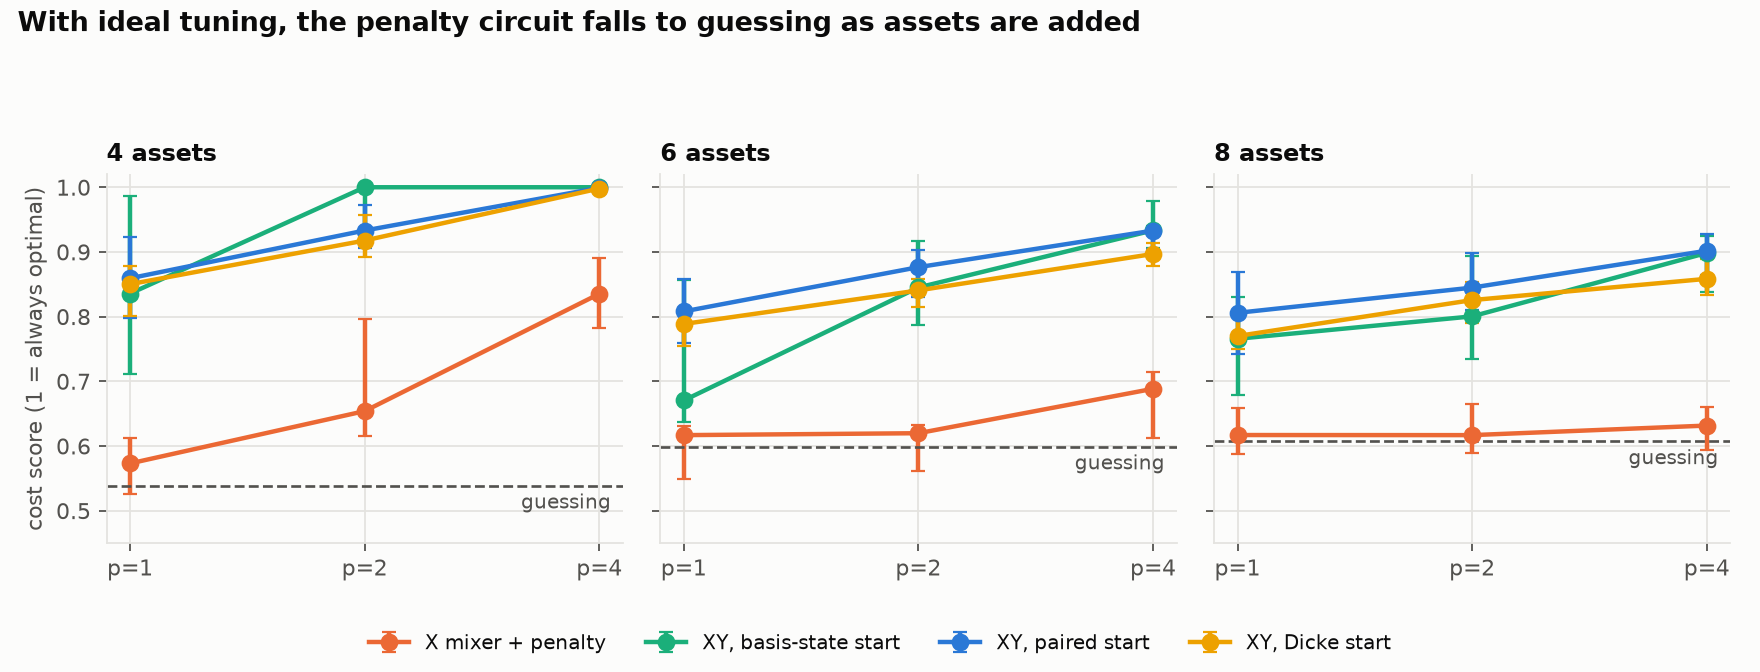

In [5]:
display(Image("figures/ansatz_ceiling.png"))

**Synthesis.** The penalty circuit (orange) sinks to the guessing line by 8 assets even with ideal
angles and a penalty weight chosen with knowledge of the answer. The failure is structural.

The fix is a mixer that cannot break the budget. An XX+YY rotation swaps a "held" and a "not held"
stock without changing how many are held, so every output is a valid portfolio and no penalty is needed.

In [6]:
problem = make_pool(prices, "test", 1, 6, 3, 30.0, seed=5)[0]
ham = build_cost_hamiltonian(problem, 0.0, gauge=True)
circuit = build_qaoa_circuit(ham, p=1, mixer="xy", budget=3, init="pairs")
circuit.draw("text", fold=120)

┌───┐     ┌─────────────────────────────┐                                                                        »
q_0: ┤ H ├──■──┤ Rz(0.3216954013591611*γ[0]) ├──────────────────────────────────────■─────────────────────────────────»
     └───┘┌─┴─┐└────────────┬───┬────────────┘          ┌───────────────┐           │ZZ((-0.011064011582852008)*γ[0]) »
q_1: ─────┤ X ├─────────────┤ X ├───────────────────────┤ Rz((-2)*γ[0]) ├───────────■─────────────────────────────────»
     ┌───┐└───┘┌────────────┴───┴─────────────┐         └───────────────┘                                             »
q_2: ┤ H ├──■──┤ Rz(0.20772415118414492*γ[0]) ├───────────────────────────────────────────────────────────────────────»
     └───┘┌─┴─┐└────────────┬───┬─────────────┘   ┌────────────────────────────┐                                      »
q_3: ─────┤ X ├─────────────┤ X ├─────────────────┤ Rz(1.383392803256422*γ[0]) ├──────────────────────────────────────»
     ┌───┐└───┘┌────────────┴───┴─────────────┐   └────────────────────────────┘                                      »
q_4: ┤ H ├──■──┤ Rz(0.12565853115069028*γ[0]) ├───────────────────────────────────────────────────────────────────────»
     └───┘┌─┴─┐└────────────┬───┬─────────────┘┌──────────────────────────────────┐                                   »
q_5: ─────┤ X ├─────────────┤ X ├──────────────┤ Rz((-0.038470886950415825)*γ[0]) ├───────────────────────────────────»
          └───┘             └───┘              └──────────────────────────────────┘                                   »
«                                                                                                       »
«q_0: ─■─────────────────────────────────■──────────────────────────────────────────────────────────────»
«      │                                 │                                                              »
«q_1: ─┼─────────────────────────────────┼─────────────────────────────■────────────────────────────────»
«      │ZZ((-0.04665601976502953)*γ[0])  │                             │ZZ((-0.10760405141217726)*γ[0]) »
«q_2: ─■─────────────────────────────────┼─────────────────────────────■────────────────────────────────»
«                                        │ZZ(0.1523619013038117*γ[0])                                   »
«q_3: ───────────────────────────────────■──────────────────────────────────────────────────────────────»
«                                                                                                       »
«q_4: ──────────────────────────────────────────────────────────────────────────────────────────────────»
«                                                                                                       »
«q_5: ──────────────────────────────────────────────────────────────────────────────────────────────────»
«                                                                                                       »
«                                                                                                      »
«q_0: ─■────────────────────────────────────────────────────────────────■──────────────────────────────»
«      │                                                                │                              »
«q_1: ─┼─────────────────────────────────■──────────────────────────────┼──────────────────────────────»
«      │                                 │                              │                              »
«q_2: ─┼─────────────────────────────────┼──────────────────────────────┼──────────────────────────────»
«      │                                 │ZZ(0.19700919277949003*γ[0])  │                              »
«q_3: ─┼─────────────────────────────────■──────────────────────────────┼──────────────────────────────»
«      │ZZ((-0.09937643867079574)*γ[0])                                 │                              »
«q_4: ─■────────────────────────────────────────────────────────────────┼──────────────────────────────»
«                

### A trap we fell into: the start state that was already the answer

Our first XY circuit started from one fixed valid portfolio and scored 100% on the 4-stock toy at
depth 1. The reason: that starting portfolio happened to be the optimum, so the best "tuning" was to do
nothing. The cell below shows it. All later results use start states that favour no stock (the paired
start or the Dicke state), on instances whose stock order is random.

In [7]:
from qpo.ansatz import initial_selection
toy_ham = build_cost_hamiltonian(toy, 0.0, gauge=True)
start = [toy.tickers[q] for q in initial_selection(4, 2)]
probs = FastQAOA(toy_ham, "xy", 2, init="spread").probabilities([0.0], [0.0])
print("fixed start state:", start, "| optimum:", list(toy.names(toy.best_index)))
print("P(optimum) with all angles set to zero:", probs[toy.best_index])

fixed start state: ['JPM', 'JNJ'] | optimum: ['JPM', 'JNJ']
P(optimum) with all angles set to zero: 1.0


## 4. A structural finding: most of this problem is sorting

Once the budget is guaranteed, the number of held stocks is a constant. That lets us move, exactly,
every part of the cost that depends on one stock at a time out of the two-qubit couplings and into
single-qubit fields (`budget_gauge` in `qpo/hamiltonian.py`, verified by brute force). What remains in
the couplings is only the genuine pair interaction: diversification.

check on feasible states: {'max_abs_error': 4.440892098500626e-16, 'operator_matches_coefficients': True, 'states_checked': 20, 'feasible_argmin_preserved': True}
total |coupling| before 0.3747 -> after 0.1751


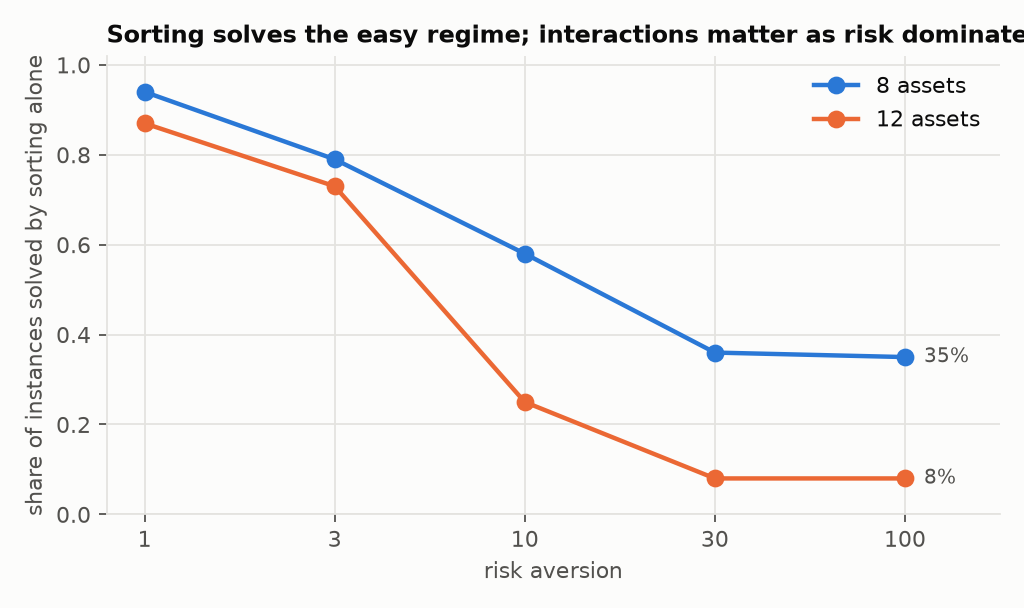

In [8]:
plain = build_cost_hamiltonian(problem, 0.0, gauge=False, normalise=False)
gauged = build_cost_hamiltonian(problem, 0.0, gauge=True, normalise=False)
print("check on feasible states:", verify(problem, gauged))
print(f"total |coupling| before {np.abs(plain.J).sum():.4f} -> after {np.abs(gauged.J).sum():.4f}")
display(Image("figures/hardness_dial.png"))

**What this means.** At ordinary risk aversion, sorting stocks by their field solves most instances
outright: there is little for *any* combinatorial solver, quantum or classical, to do. The interaction
part only matters when risk dominates (a minimum-variance style mandate), which is the regime
(risk aversion 30) used for every benchmark below. Even there the interactions carry about a tenth of
the variation in cost.

## 5. Tuning the angles: SPSA, Bayesian optimisation, and PPO

Four Fourier amplitudes are expanded into the angles of 4 layers. Tuners compared on 20 held-out
instances (2024-25), each with a noisy 1024-shot objective and a hard cap on evaluations:

* random search (the baseline every tuner must beat), SPSA, Gaussian-process Bayesian optimisation;
* a PPO policy trained once, offline, on 48 instances from 2021-23, which then proposes angles for a
  new instance with **zero** circuit evaluations.

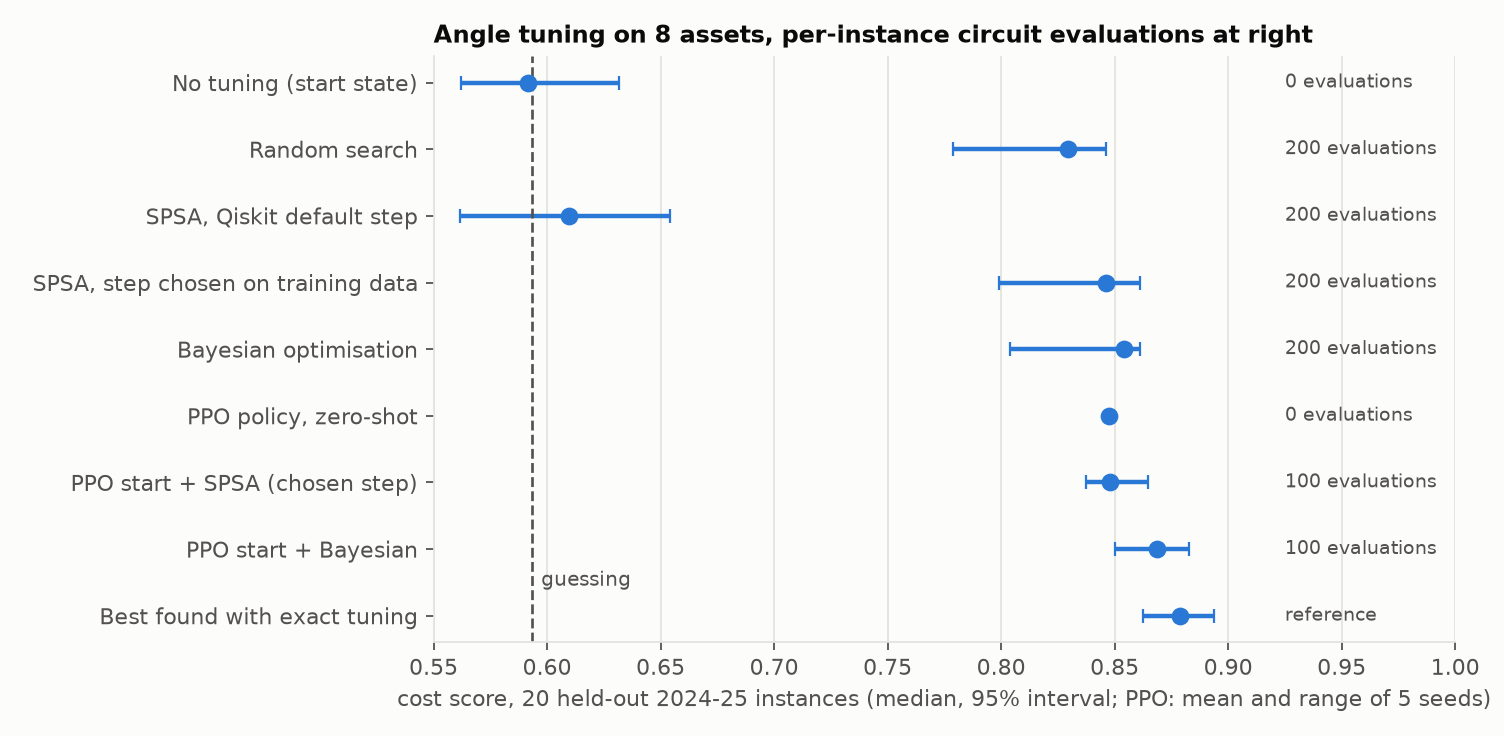

PPO offline training: 30,000 simulator evaluations per seed, about 25 s on a laptop
policy trained on 8 assets, used on 10: score 0.845 (range over seeds 0.841-0.847; exact tuning 0.869; guessing 0.640)
policy trained on 8 assets, used on 12: score 0.835 (range over seeds 0.833-0.837; exact tuning 0.863; guessing 0.662)


In [9]:
e3 = results("e03_tuners")
display(Image("figures/tuners.png"))
print(f"PPO offline training: {e3['config']['ppo_steps']:,} simulator evaluations per seed, "
      f"about {e3['ppo']['context']['train_seconds_mean']:.0f} s on a laptop")
for t in e3["transfer"]:
    print(f"policy trained on 8 assets, used on {t['n']}: score {t['ppo_context']['mean']:.3f} "
          f"(range over seeds {t['ppo_context']['min']:.3f}-{t['ppo_context']['max']:.3f}; "
          f"exact tuning {t['ceiling_fourier4']['ratio']['median']:.3f}; guessing {t['uniform_guess_ratio']:.3f})")

## 6. Brisbane: connectivity, depth and noise

`ibm_brisbane` has a heavy-hex layout: each qubit touches at most three others, but the cost function
couples every pair of stocks. Three ways to lay out one QAOA layer:

* **transpiler routing**: hand over the all-to-all circuit and let SABRE insert SWAPs;
* **swap network**: place the stocks on a line of qubits and interleave ZZ rotations with SWAPs so every
  pair meets once, at 3 two-qubit gates per pair;
* **fields only**: drop the small residual couplings, leaving a cost layer made of RZ gates (free on
  IBM hardware) and a nearest-neighbour mixer.

best line of 6 physical qubits: [122, 123, 124, 125, 126, 112]
swap-network circuit on Brisbane's gates: {'two_qubit_gates': 58, 'two_qubit_depth': 23, 'depth': 142} {'rz': 287, 'sx': 177, 'ecr': 58, 'measure': 6, 'x': 3}


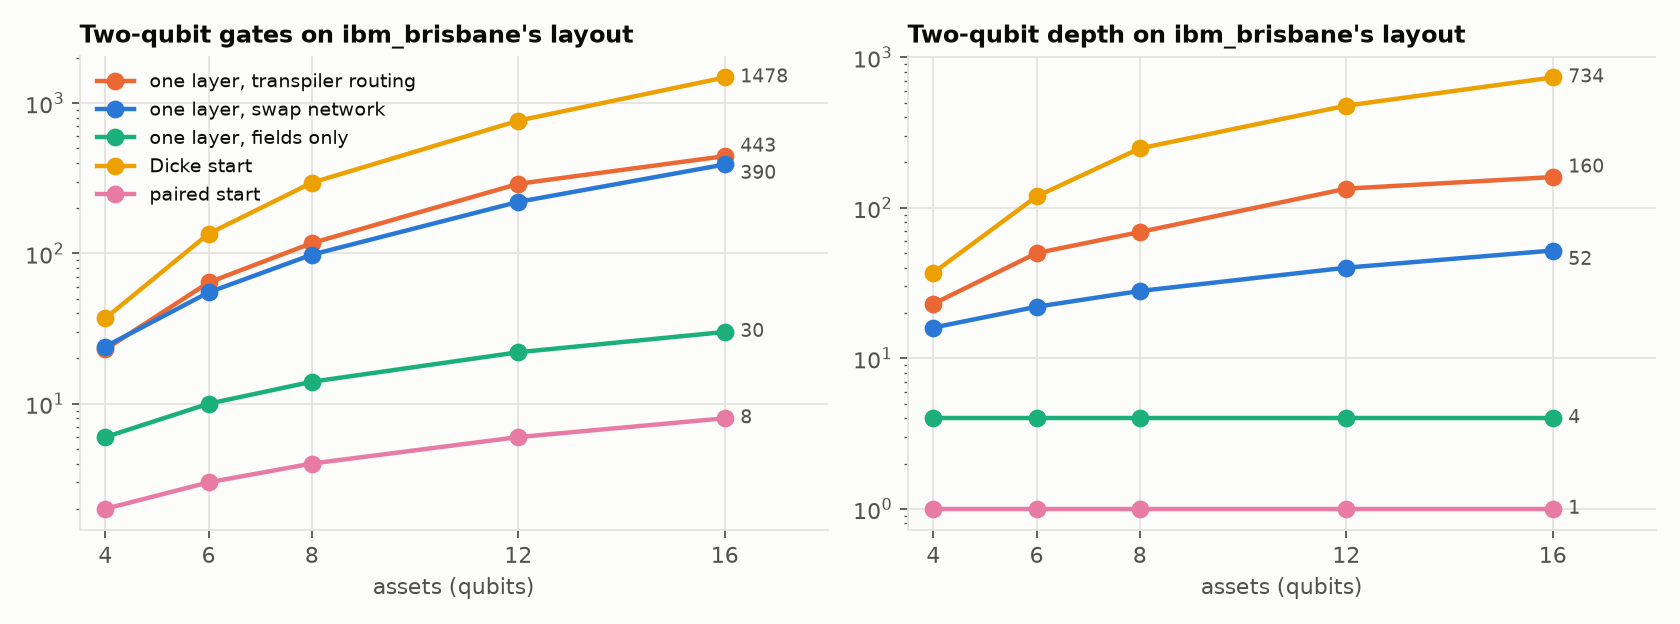

In [10]:
from qpo.hardware import get_backend, best_line, build_swap_network_circuit, transpile_for, two_qubit_stats
backend = get_backend("fake_brisbane")
line = best_line(backend, 6)
isa = transpile_for(backend, build_swap_network_circuit(ham, 1, 3, init="pairs"), initial_layout=line)
print("best line of 6 physical qubits:", line)
print("swap-network circuit on Brisbane's gates:", two_qubit_stats(isa), dict(isa.count_ops()))
display(Image("figures/gate_costs.png"))

The Dicke start, which looked best in noise-free simulation, is the most expensive piece on this
layout. The paired start does the same job with one gate per pair.

**Noisy simulation.** Angles are tuned on the ideal simulator, then each circuit is sampled 4096 times
through the `SamplerV2` primitive on an Aer simulator carrying FakeBrisbane's noise model. Mitigation:
readout-error inversion, then discarding any shot whose number of held stocks is wrong (the XY circuit
cannot produce one, so such a shot proves an error happened).

shots with the right budget: 66.3% (noise-free circuit: 100%)
cost score  noise-free 0.840 | noisy, post-selected 0.783 | guessing 0.487


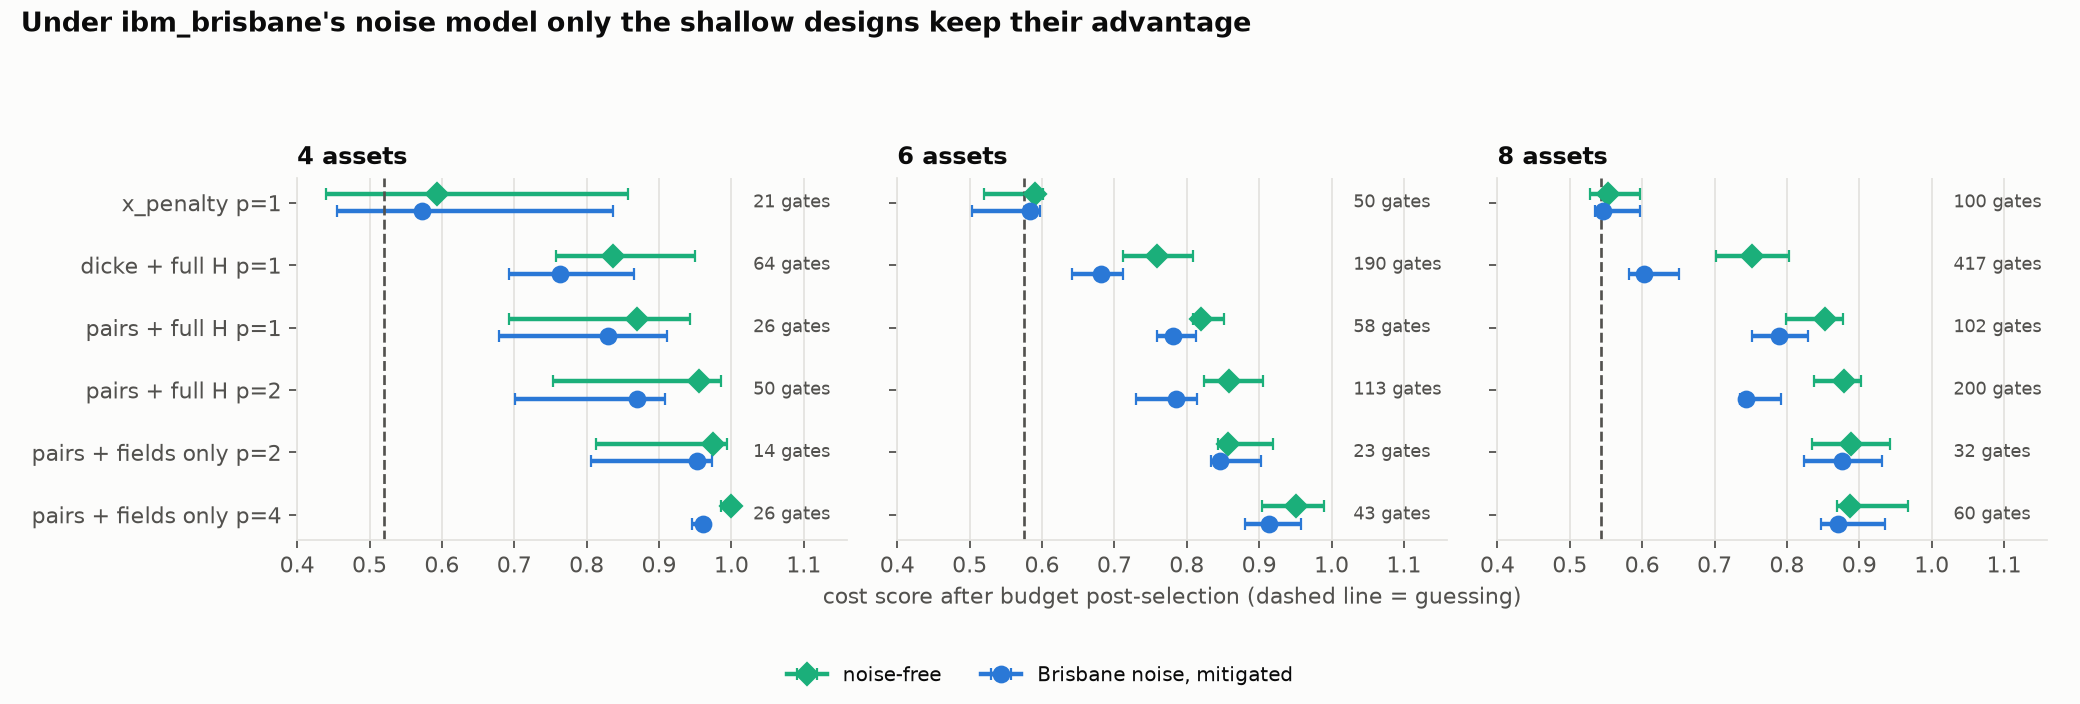

In [11]:
from qpo.hardware import noisy_simulator, sample, measured_physical_qubits
from qpo.mitigation import postselect_budget
sim_noisy = noisy_simulator(backend, seed=1)
fast = FastQAOA(ham, "xy", 3, init="pairs")
from scipy.optimize import minimize
rng = np.random.default_rng(0)
best = min((minimize(lambda x: fast.energy(x[:1], x[1:]), rng.uniform(-1, 1, 2)) for _ in range(6)), key=lambda r: r.fun)
counts = sample(sim_noisy, isa, bind_vector(best.x[:1], best.x[1:]), shots=4096)
raw = counts_to_probs(counts, 6)
kept_probs, kept = postselect_budget(raw, problem.feasible_mask)
print(f"shots with the right budget: {kept:.1%} (noise-free circuit: 100%)")
print(f"cost score  noise-free {summarise(problem, fast.probabilities(best.x[:1], best.x[1:]))['ratio']:.3f} | "
      f"noisy, post-selected {summarise(problem, kept_probs)['ratio']:.3f} | guessing {summarise(problem, raw)['ratio_uniform']:.3f}")
display(Image("figures/noisy_brisbane.png"))

## 7. Against classical methods

Same instances, risk aversion 30. "Optimum found" is the share of 40 instances solved exactly. The QAOA
row is the noise-free simulator with PPO angles and 1024 shots; its fair comparison is 1024 uniformly
random valid portfolios.

In [12]:
e5 = results("e05_classical")
print(f"{'n':>3} {'method':28s} {'optimum found':>14} {'mean gap':>9} {'cost evals':>11}")
for r in e5["baselines"]:
    print(f"{r['n']:3d} {r['method']:28s} {r['finds_optimum']:14.0%} {r['mean_gap']:9.4f} {r['median_cost_evaluations']:11.0f}")

  n method                        optimum found  mean gap  cost evals
  8 top_return                               5%    0.5255           0
  8 markowitz_rounding                      57%    0.0558          84
  8 field_ranking                           30%    0.0543           0
  8 field_ranking_plus_search              100%    0.0000          33
  8 simulated_annealing                    100%    0.0000         401
  8 random_feasible_1024                   100%    0.0000        1024
  8 qaoa_ppo_1024                          100%    0.0000        1024
 12 top_return                               0%    0.5486           0
 12 markowitz_rounding                      30%    0.0986         124
 12 field_ranking                            5%    0.0763           0
 12 field_ranking_plus_search               98%    0.0001          73
 12 simulated_annealing                     98%    0.0001         401
 12 random_feasible_1024                    60%    0.0070        1024
 12 qaoa_ppo_1024   

## 8. What we can and cannot claim

See `README.md` for the full list with numbers. In short: the circuit design changes are real and
measured; there is no quantum advantage here, and a sort plus a short local search beats every quantum
variant at these sizes. The README also states what would have to change for that to be different.

To re-run everything: `pytest tests`, then the scripts in `experiments/` in order.